In [1]:
import sys
print(sys.executable)

C:\Users\heyer\OneDrive\Desktop\one_look\.venv\Scripts\python.exe


In [2]:
import glob, os
import numpy as np
import rasterio
import matplotlib.pyplot as plt

ROOT = "../data/sen1floods11"
labels = sorted(glob.glob(f"{ROOT}/LabelHand/*.tif"))
print(len(labels), "tuiles")
print([os.path.basename(p) for p in labels[:5]])


446 tuiles
['Bolivia_103757_LabelHand.tif', 'Bolivia_129334_LabelHand.tif', 'Bolivia_195474_LabelHand.tif', 'Bolivia_23014_LabelHand.tif', 'Bolivia_233925_LabelHand.tif']


In [3]:
name = os.path.basename(labels[0]).replace("_LabelHand.tif", "")

def lire(dossier, suffixe):
    with rasterio.open(f"{ROOT}/{dossier}/{name}_{suffixe}.tif") as src:
        return src.read().astype("float32"), src

s1, src1 = lire("S1Hand", "S1Hand")
s2, src2 = lire("S2Hand", "S2Hand")
lab, _ = lire("LabelHand", "LabelHand")
jrc, _ = lire("JRCWaterHand", "JRCWaterHand")

for nom, arr in [("S1", s1), ("S2", s2), ("Label", lab), ("JRC", jrc)]:
    print(nom, arr.shape, "min", np.nanmin(arr), "max", np.nanmax(arr), "NaN", np.isnan(arr).sum())
print("Valeurs du masque :", np.unique(lab))
print("CRS :", src2.crs, "| résolution :", src2.res)

S1 (2, 512, 512) min -48.24836 max -0.69059896 NaN 321042
S2 (13, 512, 512) min 0.0 max 5662.0 NaN 0
Label (1, 512, 512) min -1.0 max 1.0 NaN 0
JRC (1, 512, 512) min 0.0 max 0.0 NaN 0
Valeurs du masque : [-1.  0.  1.]
CRS : EPSG:4326 | résolution : (8.983152841195215e-05, 8.983152841195215e-05)


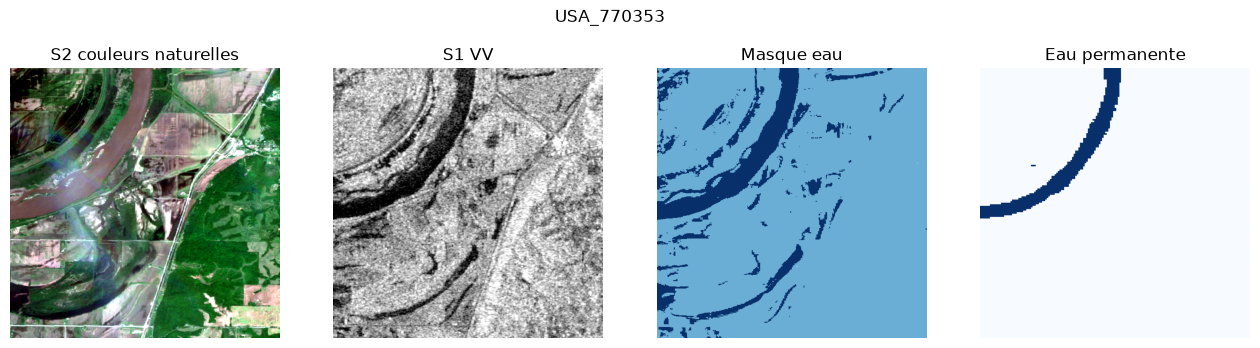

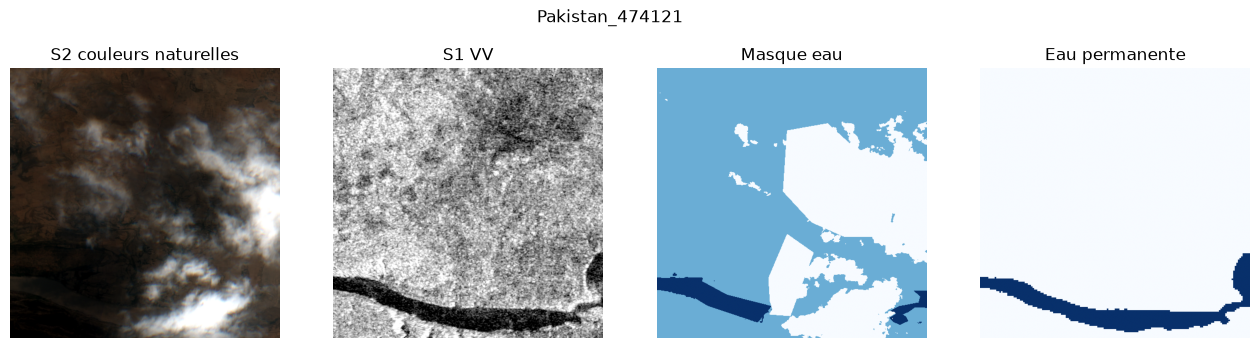

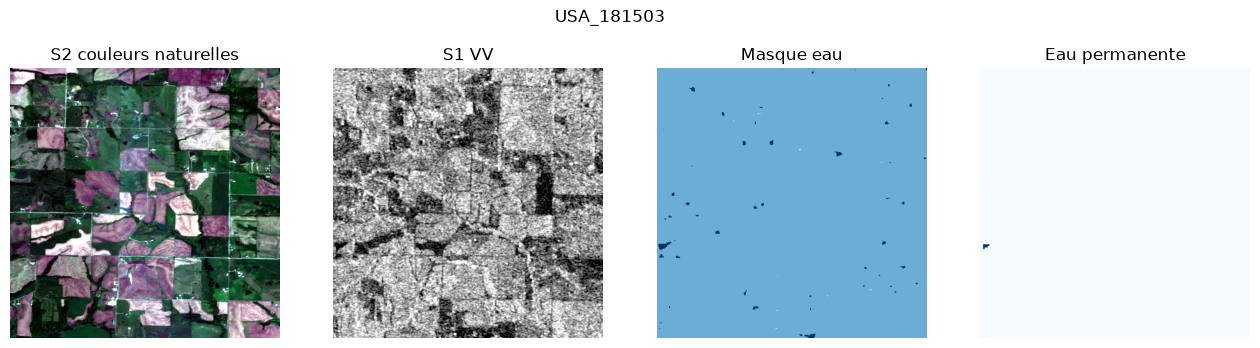

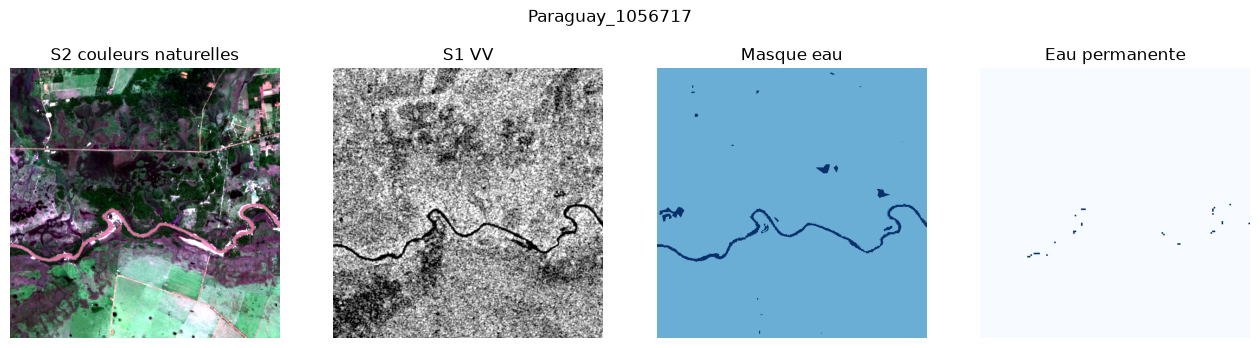

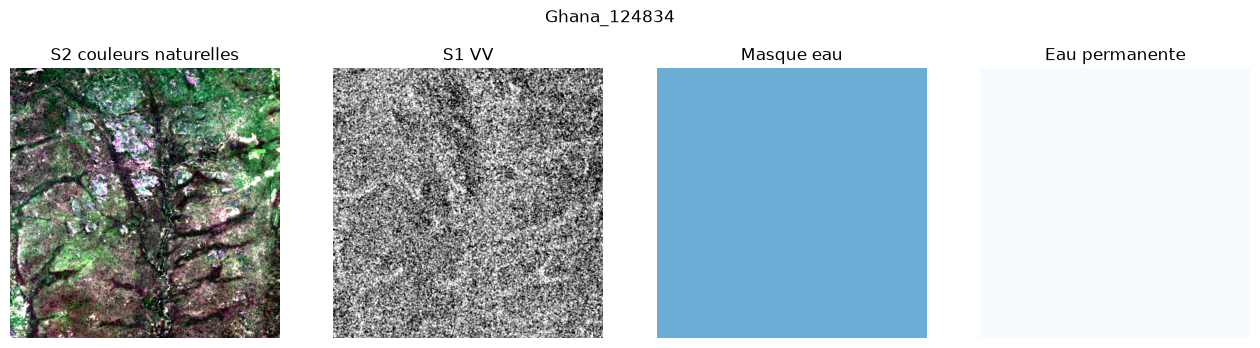

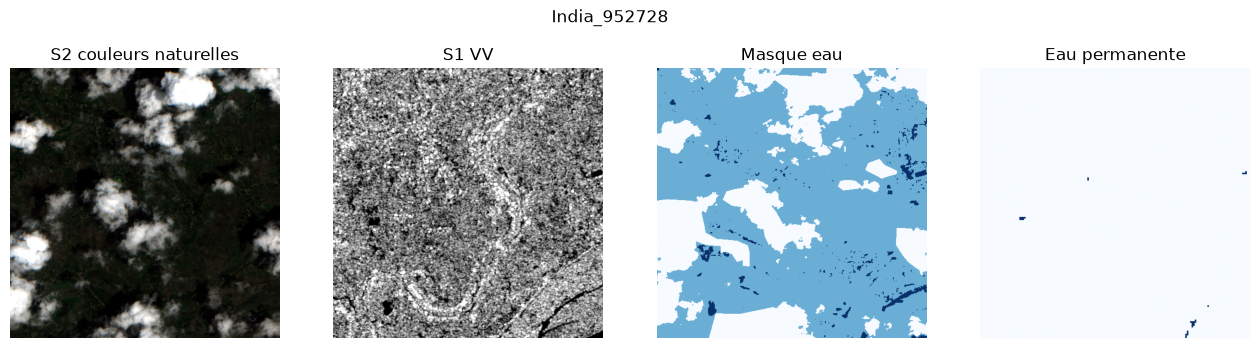

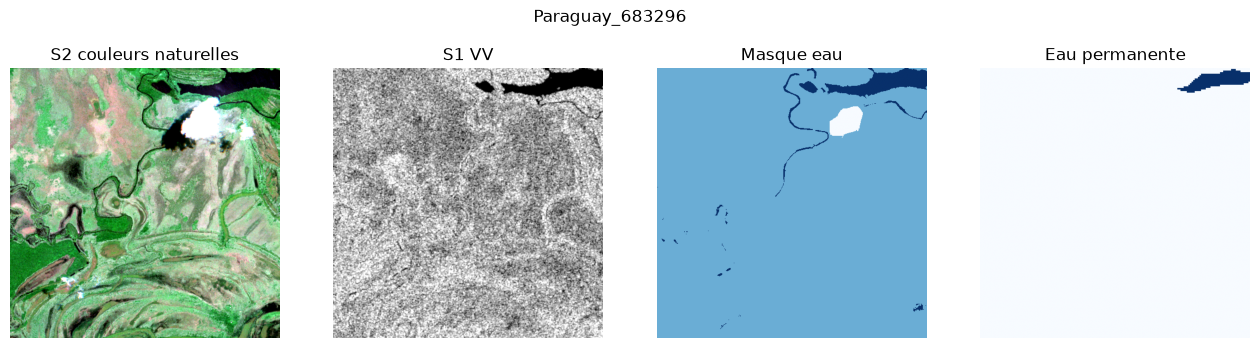

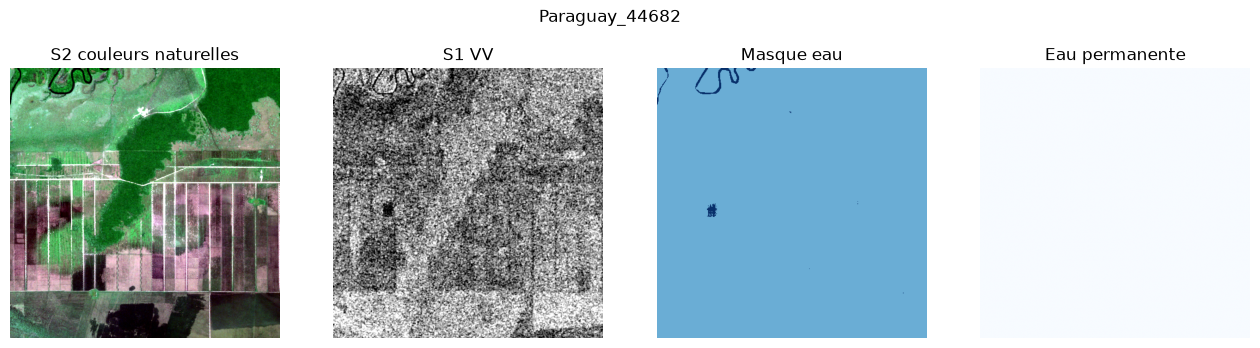

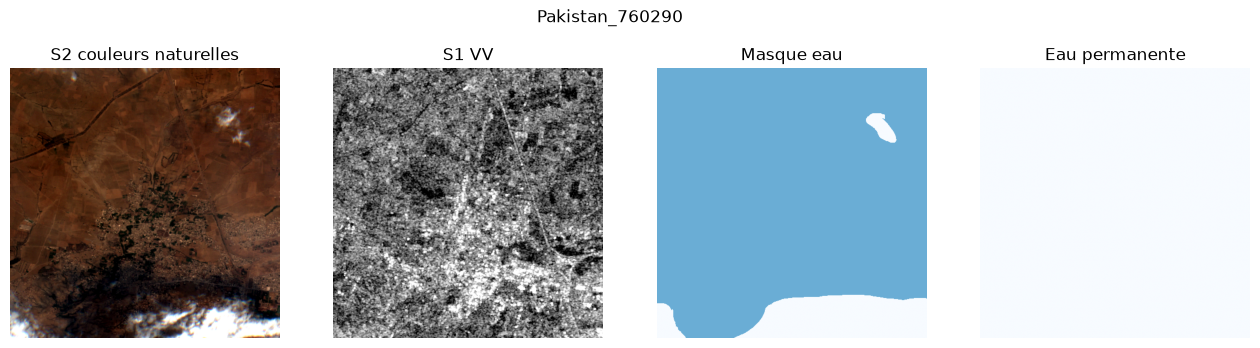

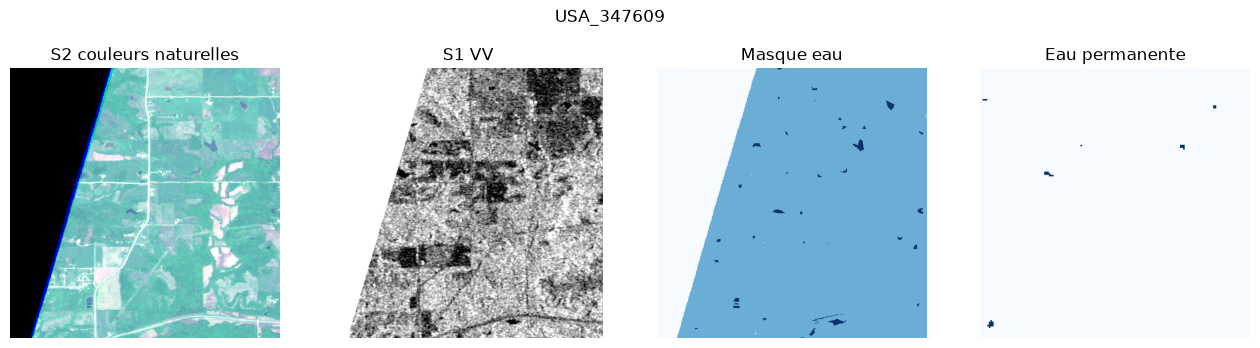

In [4]:
def etirer(img):
    """Étire le contraste entre les percentiles 2 et 98."""
    lo, hi = np.nanpercentile(img, [2, 98])
    return np.clip((img - lo) / (hi - lo + 1e-6), 0, 1)

def afficher(name):
    s1 = rasterio.open(f"{ROOT}/S1Hand/{name}_S1Hand.tif").read().astype("float32")
    s2 = rasterio.open(f"{ROOT}/S2Hand/{name}_S2Hand.tif").read().astype("float32")
    lab = rasterio.open(f"{ROOT}/LabelHand/{name}_LabelHand.tif").read(1)
    jrc = rasterio.open(f"{ROOT}/JRCWaterHand/{name}_JRCWaterHand.tif").read(1)

    rgb = np.dstack([etirer(s2[3]), etirer(s2[2]), etirer(s2[1])])  # B4, B3, B2
    fig, ax = plt.subplots(1, 4, figsize=(16, 4))
    ax[0].imshow(rgb); ax[0].set_title("S2 couleurs naturelles")
    ax[1].imshow(etirer(s1[0]), cmap="gray"); ax[1].set_title("S1 VV")
    ax[2].imshow(lab, cmap="Blues", vmin=-1, vmax=1); ax[2].set_title("Masque eau")
    ax[3].imshow(jrc, cmap="Blues", vmin=0, vmax=1); ax[3].set_title("Eau permanente")
    for a in ax: a.axis("off")
    fig.suptitle(name)
    plt.show()

import random
random.seed(0)
for p in random.sample(labels, 10):
    afficher(os.path.basename(p).replace("_LabelHand.tif", ""))

In [5]:
from collections import Counter
print(Counter(os.path.basename(p).split("_")[0] for p in labels))


Counter({'USA': 69, 'India': 68, 'Paraguay': 67, 'Ghana': 53, 'Sri-Lanka': 42, 'Mekong': 30, 'Spain': 30, 'Pakistan': 28, 'Somalia': 26, 'Nigeria': 18, 'Bolivia': 15})
